# Problem 4.3: Continuous Latent Transformer Model (Diffusion Transformer, DiT)

The continuous autoencoder of 4.1 turns every CIFAR-10 image into **5 × 8 × 8 = 320 real numbers**.
Here a **Transformer** learns the distribution of these continuous latents and generates new ones, which are decoded into
images by the 4.1 decoder.

**Model: Diffusion Transformer (DiT, Peebles & Xie, 2023).** The 8 × 8 latent grid is treated as a sequence of
**64 tokens** (one per position, 5 values each). A Transformer with adaptive layer norm (adaLN-Zero), conditioned on the
diffusion step and the class label, predicts the noise that was added to the latents (Gaussian diffusion, T = 1000,
cosine schedule). New latents are sampled with **DDIM** (50 steps) and **classifier-free guidance**.

**Target (Problem 4):** FID < 40 on CIFAR-10.

**Safety limits:** FID is checked every 10 epochs and training stops as soon as FID < 40. Training also stops after
**10 hours** (Kaggle's limit is 12 h), so the final FID and the images are always produced.

**Kaggle:** Add Input → your **4.1 notebook** output (`cae.pt`, `cae_latents.pt`; add any notebook whose output has
`cifar10_uint8.pt` to skip the CIFAR download). GPU + Internet on → **Save Version → Save & Run All (Commit)**.
Colab also works (files in `MyDrive/mm811_p4_simple`), but the tab must stay open.

## 1. Settings and storage

In [1]:
import os, glob, math, time, copy, shutil
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, TensorDataset

NOTEBOOK_START = time.time()
torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"

CONT_CH = 5               # continuous latent 5 x 8 x 8 (from 4.1)
NUM_CLASSES = 10          # label 10 = "no label" (for CFG)
T = 1000                  # diffusion steps
DIM, DEPTH, HEADS = 384, 12, 6
BATCH_SIZE = 256
LR = 2e-4
MAX_EPOCHS = 300
CHECK_EVERY = 10          # quick FID every 10 epochs; stop when below the target
TARGET_FID = 40
TRAIN_HOURS = 10.0        # stop training after this (Kaggle limit is 12 h)
P_UNCOND = 0.1
EMA_DECAY = 0.9995
DDIM_STEPS = 50
print("device:", device)

ON_KAGGLE = os.path.exists("/kaggle")
if ON_KAGGLE:
    SAVE_DIR = "/kaggle/working"
else:
    from google.colab import drive
    drive.mount("/content/drive")
    SAVE_DIR = "/content/drive/MyDrive/mm811_p4_simple"
os.makedirs(SAVE_DIR, exist_ok=True)


def find(name):
    hits = glob.glob(f"/kaggle/input/**/{name}", recursive=True) if ON_KAGGLE else []
    for p in [f"{SAVE_DIR}/{name}"] + hits:
        if os.path.exists(p):
            return p
    return None


if ON_KAGGLE:   # copy inputs (and a previous run's checkpoint, to resume) into the working folder
    for name in ["cae.pt", "cae_latents.pt", "cifar10_uint8.pt", "dit_ckpt.pt", "dit_best.pt"]:
        p = find(name)
        if p and not os.path.exists(f"{SAVE_DIR}/{name}"):
            shutil.copy(p, SAVE_DIR); print("found", p)
assert find("cae.pt") and find("cae_latents.pt"), "cae.pt / cae_latents.pt not found: add the 4.1 notebook output as input"
print("files:", sorted(os.listdir(SAVE_DIR)))

device: cuda
found /kaggle/input/notebooks/rachdewanjee/notebooka5bf4cb3eb/cae.pt
found /kaggle/input/notebooks/rachdewanjee/notebooka5bf4cb3eb/cae_latents.pt
found /kaggle/input/notebooks/rachdewanjee/notebook72fb9fed72/cifar10_uint8.pt
files: ['__notebook__.ipynb', 'cae.pt', 'cae_latents.pt', 'cifar10_uint8.pt']


## 2. CIFAR-10 (labels for conditioning, training images for flips, test images for FID)

In [2]:
cache = find("cifar10_uint8.pt")
if cache:
    cifar = torch.load(cache)
    print("loaded CIFAR-10 from", cache)
else:
    from torchvision import datasets
    tr = datasets.CIFAR10("./data", train=True, download=True)
    te = datasets.CIFAR10("./data", train=False, download=True)
    cifar = {"train_x": torch.from_numpy(tr.data).permute(0, 3, 1, 2).contiguous(), "train_y": torch.tensor(tr.targets),
             "test_x": torch.from_numpy(te.data).permute(0, 3, 1, 2).contiguous(), "test_y": torch.tensor(te.targets)}
    torch.save(cifar, f"{SAVE_DIR}/cifar10_uint8.pt")
    print("downloaded CIFAR-10 and saved cifar10_uint8.pt")
to_float = lambda x: x.to(device).float().div(255)

loaded CIFAR-10 from /kaggle/working/cifar10_uint8.pt


## 3. Load the 4.1 continuous autoencoder
Same class as in 4.1 so `cae.pt` loads exactly. The encoder makes latents for flipped images; the decoder turns generated
latents into images.

In [3]:
def block(c_in, c_out):
    return nn.Sequential(nn.Conv2d(c_in, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU())


class Autoencoder(nn.Module):
    def __init__(self, latent_ch, discrete=False):
        super().__init__()
        self.discrete = discrete
        self.encoder = nn.Sequential(
            block(3, 64),
            nn.Conv2d(64, 128, 4, stride=2, padding=1), nn.BatchNorm2d(128), nn.ReLU(),
            block(128, 128),
            nn.Conv2d(128, 256, 4, stride=2, padding=1), nn.BatchNorm2d(256), nn.ReLU(),
            block(256, 256),
            nn.Conv2d(256, latent_ch, 3, padding=1),
        )
        self.decoder = nn.Sequential(
            block(latent_ch, 256),
            block(256, 256),
            nn.ConvTranspose2d(256, 128, 4, stride=2, padding=1), nn.BatchNorm2d(128), nn.ReLU(),
            block(128, 128),
            nn.ConvTranspose2d(128, 64, 4, stride=2, padding=1), nn.BatchNorm2d(64), nn.ReLU(),
            nn.Conv2d(64, 3, 3, padding=1),
            nn.Sigmoid(),
        )


cae = Autoencoder(CONT_CH).to(device)
cae.load_state_dict(torch.load(find("cae.pt"), map_location=device))
cae.eval()


@torch.no_grad()
def encode(imgs_uint8):
    return torch.cat([cae.encoder(to_float(imgs_uint8[i:i + 500])).cpu() for i in range(0, len(imgs_uint8), 500)])


def show_grid(images, title, path=None, nrow=8):
    rows = math.ceil(len(images) / nrow)
    fig, axes = plt.subplots(rows, nrow, figsize=(nrow * 1.3, rows * 1.3))
    for ax in axes.flat:
        ax.axis("off")
    for i, img in enumerate(images):
        axes.flat[i].imshow(img.permute(1, 2, 0).clamp(0, 1))
    fig.suptitle(title); plt.tight_layout()
    if path:
        plt.savefig(path, dpi=120)
    plt.show()

## 4. Latents: originals + horizontally flipped, normalized per channel
The raw latents have a large scale (std ≈ 6), so each of the 5 channels is normalized to mean 0 and standard deviation 1
using the training latents. Generated latents are un-normalized before decoding.

re-encoded vs saved latents: max difference 0.00e+00
per-channel mean: [-0.399, 0.212, -0.364, 1.257, -1.131]
per-channel std:  [4.832, 8.496, 5.905, 5.522, 4.208]
normalized x: (100000, 5, 8, 8) | clip predicted x0 to +-3.69


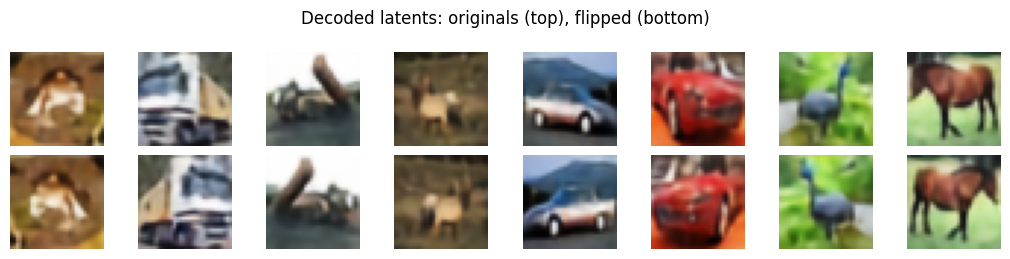

In [4]:
lat = torch.load(find("cae_latents.pt"))
z_train, z_test = lat["train"].float(), lat["test"].float()          # (50000, 5, 8, 8), (10000, 5, 8, 8)
train_y, test_y = cifar["train_y"], cifar["test_y"]

check = encode(cifar["train_x"][:500])
print(f"re-encoded vs saved latents: max difference {(check - z_train[:500]).abs().max():.2e}")

z_flip = encode(cifar["train_x"].flip(-1))
MU = z_train.mean(dim=(0, 2, 3), keepdim=True)                        # per-channel mean (1, 5, 1, 1)
SD = z_train.std(dim=(0, 2, 3), keepdim=True)                         # per-channel std
norm = lambda z: (z - MU) / SD
x_train = norm(torch.cat([z_train, z_flip]))
y_train = torch.cat([train_y, train_y])
CLIP = float(x_train.abs().flatten().quantile(0.9995)) if x_train.numel() < 2**24 else \
       float(x_train.abs().flatten()[torch.randperm(x_train.numel())[:10_000_000]].quantile(0.9995))
print("per-channel mean:", [round(v, 3) for v in MU.flatten().tolist()])
print("per-channel std: ", [round(v, 3) for v in SD.flatten().tolist()])
print(f"normalized x: {tuple(x_train.shape)} | clip predicted x0 to +-{CLIP:.2f}")
train_loader = DataLoader(TensorDataset(x_train, y_train), batch_size=BATCH_SIZE, shuffle=True, drop_last=True)


@torch.no_grad()
def decode(x_norm):
    z = x_norm.float().cpu() * SD + MU
    return torch.cat([cae.decoder(z[i:i + 500].to(device)).cpu() for i in range(0, len(z), 500)])


show_grid(torch.cat([decode(x_train[:8]), decode(x_train[len(z_train):len(z_train) + 8])]),
          "Decoded latents: originals (top), flipped (bottom)")

## 5. Noise schedule (cosine, T = 1000)
Forward process: **x_t = √ᾱ_t · x_0 + √(1 − ᾱ_t) · ε**, ε ~ N(0, I).

In [5]:
def cosine_alpha_bar(T, s=0.008):
    steps = torch.arange(T + 1, dtype=torch.float64) / T
    f = torch.cos((steps + s) / (1 + s) * math.pi / 2) ** 2
    return f / f[0]

ab = cosine_alpha_bar(T)
betas = (1 - ab[1:] / ab[:-1]).clamp(max=0.999).float().to(device)
alpha_bar = torch.cumprod(1 - betas, dim=0)


def q_sample(x0, t, noise):
    a = alpha_bar[t].view(-1, 1, 1, 1)
    return a.sqrt() * x0 + (1 - a).sqrt() * noise

## 6. The Transformer (DiT)
- **Tokens:** each of the 64 positions of the 8 × 8 grid is one token; its 5 latent values are mapped to a vector of size
  384 by a linear layer, and a fixed 2-D sine-cosine position embedding is added.
- **Conditioning:** the diffusion step t (sinusoidal embedding + MLP) and the class label (embedding; label 10 = none) are
  added into one conditioning vector c.
- **DiT blocks (×12):** self-attention and an MLP, each preceded by a layer norm whose scale and shift are predicted from c
  (adaLN), and followed by a gate that is also predicted from c. The gates start at zero (adaLN-Zero), so every block
  starts as the identity.
- **Output:** a final adaLN layer and a linear layer give 5 values per token = the predicted noise ε (5 × 8 × 8).

In [6]:
def timestep_embedding(t, dim):
    half = dim // 2
    freqs = torch.exp(-math.log(10000) * torch.arange(half, device=t.device) / half)
    args = t.float()[:, None] * freqs[None]
    return torch.cat([args.sin(), args.cos()], dim=1)


def sincos_2d(dim, size=8):
    y, x = torch.meshgrid(torch.arange(size, dtype=torch.float32), torch.arange(size, dtype=torch.float32), indexing="ij")
    def emb(pos, d):
        omega = 1.0 / 10000 ** (torch.arange(d // 2, dtype=torch.float32) / (d // 2))
        out = pos.flatten()[:, None] * omega[None]
        return torch.cat([out.sin(), out.cos()], dim=1)
    return torch.cat([emb(y, dim // 2), emb(x, dim // 2)], dim=1)[None]      # (1, 64, dim)


def modulate(x, shift, scale):
    return x * (1 + scale[:, None]) + shift[:, None]


class DiTBlock(nn.Module):
    def __init__(self, dim, heads):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim, elementwise_affine=False, eps=1e-6)
        self.attn = nn.MultiheadAttention(dim, heads, batch_first=True)
        self.norm2 = nn.LayerNorm(dim, elementwise_affine=False, eps=1e-6)
        self.mlp = nn.Sequential(nn.Linear(dim, 4 * dim), nn.GELU(approximate="tanh"), nn.Linear(4 * dim, dim))
        self.ada = nn.Sequential(nn.SiLU(), nn.Linear(dim, 6 * dim))
        nn.init.zeros_(self.ada[-1].weight); nn.init.zeros_(self.ada[-1].bias)      # adaLN-Zero

    def forward(self, x, c):
        s1, sc1, g1, s2, sc2, g2 = self.ada(c).chunk(6, dim=1)
        h = modulate(self.norm1(x), s1, sc1)
        x = x + g1[:, None] * self.attn(h, h, h, need_weights=False)[0]
        x = x + g2[:, None] * self.mlp(modulate(self.norm2(x), s2, sc2))
        return x


class DiT(nn.Module):
    def __init__(self, dim=DIM, depth=DEPTH, heads=HEADS):
        super().__init__()
        self.dim = dim
        self.inp = nn.Linear(CONT_CH, dim)
        self.register_buffer("pos", sincos_2d(dim))
        self.t_mlp = nn.Sequential(nn.Linear(256, dim), nn.SiLU(), nn.Linear(dim, dim))
        self.y_emb = nn.Embedding(NUM_CLASSES + 1, dim)
        self.blocks = nn.ModuleList([DiTBlock(dim, heads) for _ in range(depth)])
        self.norm = nn.LayerNorm(dim, elementwise_affine=False, eps=1e-6)
        self.ada = nn.Sequential(nn.SiLU(), nn.Linear(dim, 2 * dim))
        self.out = nn.Linear(dim, CONT_CH)
        nn.init.zeros_(self.ada[-1].weight); nn.init.zeros_(self.ada[-1].bias)
        nn.init.zeros_(self.out.weight); nn.init.zeros_(self.out.bias)

    def forward(self, x, t, y):
        B = x.shape[0]
        h = self.inp(x.flatten(2).transpose(1, 2)) + self.pos                 # (B, 64, dim)
        c = self.t_mlp(timestep_embedding(t, 256)) + self.y_emb(y)
        for blk in self.blocks:
            h = blk(h, c)
        shift, scale = self.ada(c).chunk(2, dim=1)
        h = self.out(modulate(self.norm(h), shift, scale))                     # (B, 64, 5)
        return h.transpose(1, 2).reshape(B, CONT_CH, 8, 8)


model = DiT().to(device)
ema = copy.deepcopy(model).eval().requires_grad_(False)
print("parameters:", sum(p.numel() for p in model.parameters()))

parameters: 32470277


## 7. DDIM sampler with classifier-free guidance
ε̂ = ε_u + w · (ε_c − ε_u); x̂_0 = (x_t − √(1−ᾱ_t) ε̂) / √ᾱ_t (clipped to the range of the training latents);
x_s = √ᾱ_s · x̂_0 + √(1−ᾱ_s) · ε̂ (η = 0).

In [7]:
@torch.no_grad()
def ddim_sample(net, labels, steps=DDIM_STEPS, w=2.0):
    net.eval()
    n = len(labels)
    y = labels.to(device)
    y_null = torch.full_like(y, NUM_CLASSES)
    x = torch.randn(n, CONT_CH, 8, 8, device=device)
    times = torch.linspace(T - 1, 0, steps).round().long().tolist()
    for i, t in enumerate(times):
        tt = torch.full((2 * n,), t, device=device, dtype=torch.long)
        with torch.autocast("cuda", dtype=torch.float16, enabled=use_amp):
            eps_c, eps_u = net(torch.cat([x, x]), tt, torch.cat([y, y_null])).float().chunk(2)
        eps = eps_u + w * (eps_c - eps_u)
        a_t = alpha_bar[t]
        x0 = ((x - (1 - a_t).sqrt() * eps) / a_t.sqrt()).clamp(-CLIP, CLIP)
        if i == len(times) - 1:
            x = x0
        else:
            eps = (x - a_t.sqrt() * x0) / (1 - a_t).sqrt()
            a_s = alpha_bar[times[i + 1]]
            x = a_s.sqrt() * x0 + (1 - a_s).sqrt() * eps
    return x.cpu()


def balanced_labels(n):
    return torch.arange(n) % NUM_CLASSES

## 8. FID setup

In [8]:
!pip -q install torchmetrics[image]
from torchmetrics.image.fid import FrechetInceptionDistance

to_uint8 = lambda imgs: (imgs.clamp(0, 1) * 255).to(torch.uint8)
fid = FrechetInceptionDistance(feature=2048, reset_real_features=False).to(device)
for i in range(0, 10000, 500):
    fid.update(cifar["test_x"][i:i + 500].to(device), real=True)


def fid_of(fake_imgs):
    fid.reset()
    for i in range(0, len(fake_imgs), 500):
        fid.update(to_uint8(fake_imgs[i:i + 500]).to(device), real=False)
    return fid.compute().item()


def fid_of_model(net, n, w, seed=3):
    torch.manual_seed(seed)
    labels = balanced_labels(n)
    x = torch.cat([ddim_sample(net, labels[i:i + 500], w=w) for i in range(0, n, 500)])
    return fid_of(decode(x))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 85.6/85.6 kB 1.8 MB/s eta 0:00:00


Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:00<00:00, 245MB/s]


## 9. Training (stops at FID < 40, or after 10 hours)
Loss: mean squared error between the added noise and the predicted noise (DDPM objective). The label is replaced by
"no label" 10% of the time. Every 10 epochs a quick FID on 5,000 images is measured with w = 2, 3 and 4; the best model is
saved as `dit_best.pt`. A checkpoint is saved every epoch (`dit_ckpt.pt`), so a stopped run can be resumed.

Epoch   1 | train loss 0.5588 | test loss (EMA) 0.9501 | 119s | 0.06 h total
Epoch   2 | train loss 0.3626 | test loss (EMA) 0.8630 | 120s | 0.09 h total
Epoch   3 | train loss 0.3495 | test loss (EMA) 0.7579 | 120s | 0.12 h total
Epoch   4 | train loss 0.3448 | test loss (EMA) 0.6854 | 120s | 0.16 h total
Epoch   5 | train loss 0.3415 | test loss (EMA) 0.6389 | 120s | 0.19 h total
Epoch   6 | train loss 0.3380 | test loss (EMA) 0.5830 | 120s | 0.22 h total
Epoch   7 | train loss 0.3367 | test loss (EMA) 0.5089 | 121s | 0.26 h total
Epoch   8 | train loss 0.3361 | test loss (EMA) 0.4416 | 121s | 0.29 h total
Epoch   9 | train loss 0.3360 | test loss (EMA) 0.3967 | 120s | 0.33 h total
Epoch  10 | train loss 0.3337 | test loss (EMA) 0.3694 | 120s | 0.36 h total
   quick FID @ epoch 10: w=2.0: 171.0, w=3.0: 157.1, w=4.0: 144.5  (671s)
   new best model saved (quick FID 144.5, w = 4.0)
Epoch  11 | train loss 0.3311 | test loss (EMA) 0.3531 | 121s | 0.58 h total
Epoch  12 | train loss 0.332

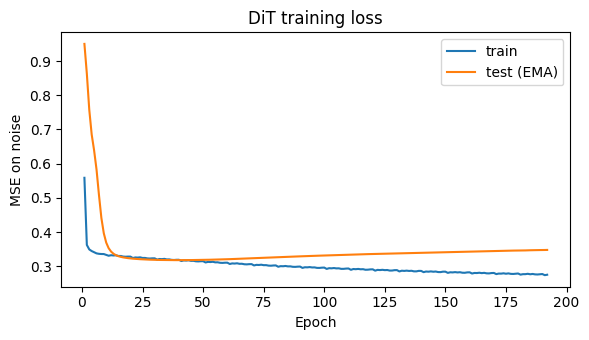

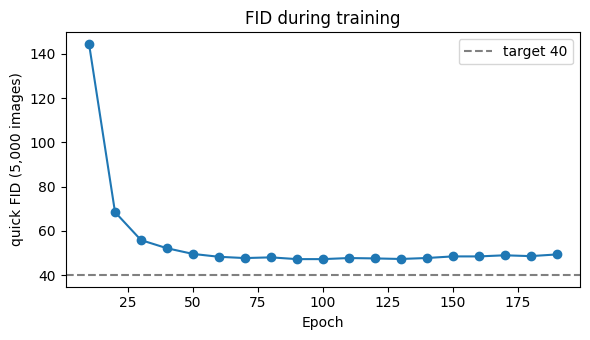

In [9]:
def loss_fn(net, x0, y):
    t = torch.randint(0, T, (x0.shape[0],), device=x0.device)
    noise = torch.randn_like(x0)
    y = torch.where(torch.rand(y.shape, device=y.device) < P_UNCOND, torch.full_like(y, NUM_CLASSES), y)
    with torch.autocast("cuda", dtype=torch.float16, enabled=use_amp):
        pred = net(q_sample(x0, t, noise), t, y)
    return F.mse_loss(pred.float(), noise)


@torch.no_grad()
def test_loss(net, n=2000):
    net.eval()
    n = min(n, len(z_test))
    g = torch.Generator(device=device).manual_seed(0)
    x0, y = norm(z_test[:n]).to(device), test_y[:n].to(device)
    t = torch.randint(0, T, (n,), device=device, generator=g)
    noise = torch.randn(x0.shape, device=device, generator=g)
    with torch.autocast("cuda", dtype=torch.float16, enabled=use_amp):
        pred = net(q_sample(x0, t, noise), t, y)
    return F.mse_loss(pred.float(), noise).item()


optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.0)
scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lambda s: min(1.0, (s + 1) / 1000))
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

CKPT, BEST = f"{SAVE_DIR}/dit_ckpt.pt", f"{SAVE_DIR}/dit_best.pt"
start_epoch, train_losses, test_losses, checks = 1, [], [], []
best_fid, best_w = float("inf"), 3.0
if os.path.exists(CKPT):
    ck = torch.load(CKPT, map_location=device)
    model.load_state_dict(ck["model"]); ema.load_state_dict(ck["ema"])
    optimizer.load_state_dict(ck["opt"]); scheduler.load_state_dict(ck["sched"]); scaler.load_state_dict(ck["scaler"])
    start_epoch, train_losses, test_losses = ck["epoch"] + 1, ck["train_losses"], ck["test_losses"]
    checks, best_fid, best_w = ck["checks"], ck["best_fid"], ck["best_w"]
    print(f"resuming from epoch {start_epoch} | best quick FID so far {best_fid:.1f}")

done = best_fid < TARGET_FID
for epoch in range(start_epoch, MAX_EPOCHS + 1):
    hours = (time.time() - NOTEBOOK_START) / 3600
    if done or hours > TRAIN_HOURS:
        if not done:
            print(f"time budget reached ({hours:.1f} h) -> stopping training")
        break
    model.train()
    running, t0 = 0.0, time.time()
    for x0, y in train_loader:
        x0, y = x0.to(device), y.to(device)
        loss = loss_fn(model, x0, y)
        optimizer.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer); scaler.update(); scheduler.step()
        with torch.no_grad():
            for pe, pm in zip(ema.parameters(), model.parameters()):
                pe.lerp_(pm, 1 - EMA_DECAY)
        running += loss.item()

    train_losses.append(running / len(train_loader))
    test_losses.append(test_loss(ema))
    print(f"Epoch {epoch:3d} | train loss {train_losses[-1]:.4f} | test loss (EMA) {test_losses[-1]:.4f} "
          f"| {time.time() - t0:.0f}s | {(time.time() - NOTEBOOK_START) / 3600:.2f} h total")

    if epoch % CHECK_EVERY == 0:
        t1 = time.time()
        scores = {w: fid_of_model(ema, 5000, w) for w in [2.0, 3.0, 4.0]}
        w_best = min(scores, key=scores.get)
        checks.append((epoch, scores[w_best], w_best))
        print(f"   quick FID @ epoch {epoch}: " + ", ".join(f"w={w}: {v:.1f}" for w, v in scores.items())
              + f"  ({time.time() - t1:.0f}s)")
        if scores[w_best] < best_fid:
            best_fid, best_w = scores[w_best], w_best
            torch.save({"ema": ema.state_dict(), "w": best_w, "epoch": epoch, "quick_fid": best_fid,
                        "MU": MU, "SD": SD, "CLIP": CLIP}, BEST)
            print(f"   new best model saved (quick FID {best_fid:.1f}, w = {best_w})")
        if best_fid < TARGET_FID:
            print(f"   TARGET REACHED: quick FID {best_fid:.1f} < {TARGET_FID} -> stopping training")
            done = True

    torch.save({"model": model.state_dict(), "ema": ema.state_dict(), "opt": optimizer.state_dict(),
                "sched": scheduler.state_dict(), "scaler": scaler.state_dict(), "epoch": epoch,
                "train_losses": train_losses, "test_losses": test_losses,
                "checks": checks, "best_fid": best_fid, "best_w": best_w}, CKPT)

if os.path.exists(BEST):
    best = torch.load(BEST, map_location=device)
    ema.load_state_dict(best["ema"]); best_w = best["w"]
    print(f"Using best model: epoch {best['epoch']}, quick FID {best['quick_fid']:.1f}, w = {best_w}")
else:
    print("no quick FID check yet: using the current EMA model")

plt.figure(figsize=(6, 3.5))
plt.plot(range(1, len(train_losses) + 1), train_losses, label="train")
plt.plot(range(1, len(test_losses) + 1), test_losses, label="test (EMA)")
plt.xlabel("Epoch"); plt.ylabel("MSE on noise"); plt.title("DiT training loss")
plt.legend(); plt.tight_layout(); plt.savefig(f"{SAVE_DIR}/dit_loss.png", dpi=120); plt.show()
if checks:
    plt.figure(figsize=(6, 3.5))
    plt.plot([c[0] for c in checks], [c[1] for c in checks], "o-")
    plt.axhline(TARGET_FID, color="gray", linestyle="--", label="target 40")
    plt.xlabel("Epoch"); plt.ylabel("quick FID (5,000 images)"); plt.title("FID during training")
    plt.legend(); plt.tight_layout(); plt.savefig(f"{SAVE_DIR}/dit_fid_curve.png", dpi=120); plt.show()

## 10. Generated images (one row per class)

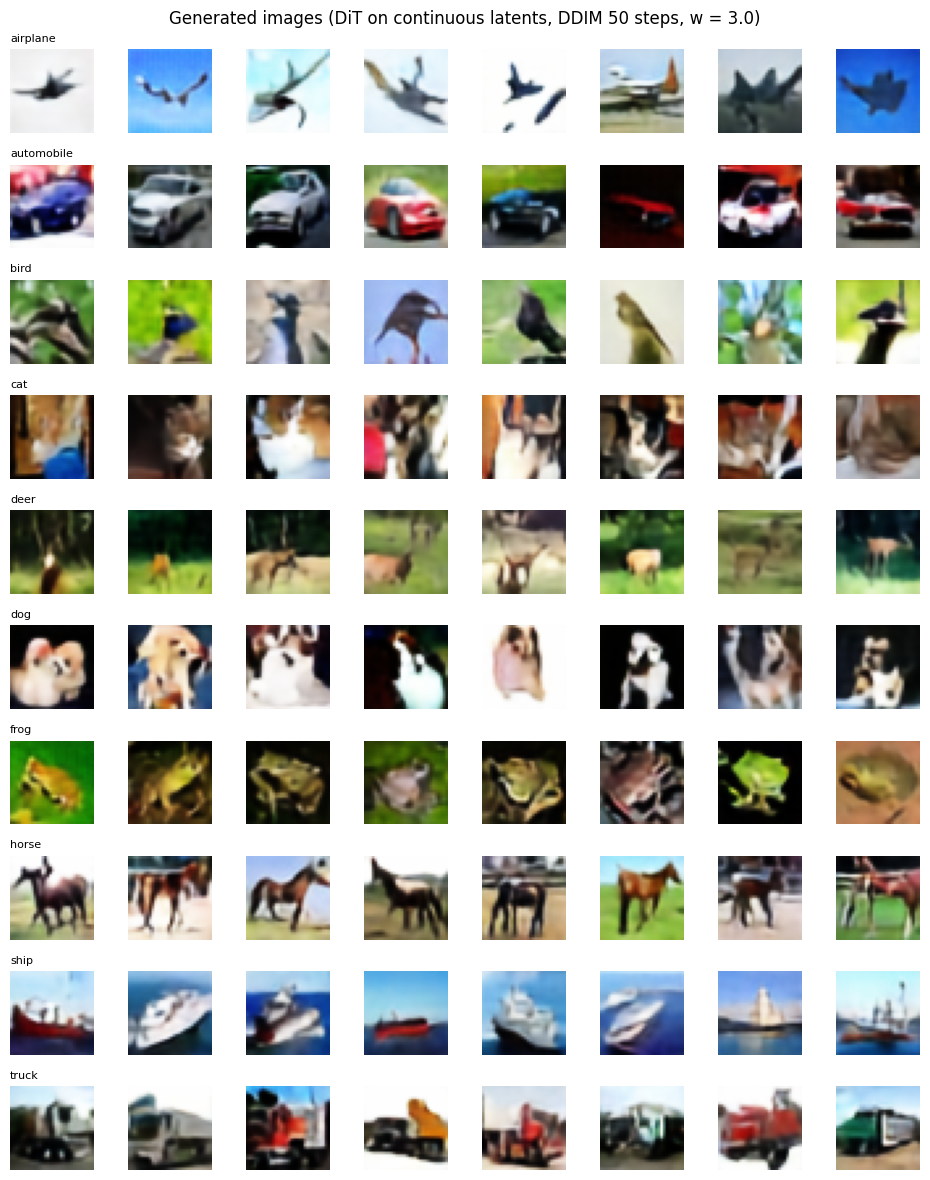

In [10]:
CLASSES = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]
torch.manual_seed(0)
labels = torch.arange(NUM_CLASSES).repeat_interleave(8)
imgs = decode(ddim_sample(ema, labels, w=best_w))
fig, axes = plt.subplots(NUM_CLASSES, 8, figsize=(8 * 1.2, NUM_CLASSES * 1.2))
for i in range(NUM_CLASSES * 8):
    ax = axes[i // 8, i % 8]
    ax.imshow(imgs[i].permute(1, 2, 0).clamp(0, 1)); ax.axis("off")
    if i % 8 == 0:
        ax.set_title(CLASSES[i // 8], loc="left", fontsize=8)
plt.suptitle(f"Generated images (DiT on continuous latents, DDIM {DDIM_STEPS} steps, w = {best_w})")
plt.tight_layout(); plt.savefig(f"{SAVE_DIR}/dit_samples.png", dpi=120); plt.show()

## 11. Final FID (target < 40)
10,000 generated images (1,000 per class) against the 10,000 real CIFAR-10 test images. Guidance strengths around the best
one are tested. The first line scores the 4.1 autoencoder's own reconstructions: the best FID possible with this decoder.

In [11]:
N_FID = 10000
results = {"Autoencoder recon (best possible)": fid_of(decode(norm(z_test[:N_FID])))}
for w in sorted({max(1.5, best_w - 1.0), best_w, best_w + 1.0}):
    t0 = time.time()
    results[f"DDIM {DDIM_STEPS} steps, w = {w}"] = fid_of_model(ema, N_FID, w)
    print(f"w = {w}: FID {results[f'DDIM {DDIM_STEPS} steps, w = {w}']:.1f}  ({time.time() - t0:.0f}s)")

best_name = min((k for k in results if k.startswith("DDIM")), key=results.get)
print()
for k, v in results.items():
    print(f"{k:<36}{v:6.1f}   {'< 40 MET' if v < 40 else '>= 40 NOT MET'}")
print(f"\nBest: {best_name}, FID {results[best_name]:.1f} -> target < 40:", "MET" if results[best_name] < 40 else "NOT MET")

w = 2.0: FID 47.5  (443s)
w = 3.0: FID 44.6  (443s)
w = 4.0: FID 46.2  (444s)

Autoencoder recon (best possible)     34.4   < 40 MET
DDIM 50 steps, w = 2.0                47.5   >= 40 NOT MET
DDIM 50 steps, w = 3.0                44.6   >= 40 NOT MET
DDIM 50 steps, w = 4.0                46.2   >= 40 NOT MET

Best: DDIM 50 steps, w = 3.0, FID 44.6 -> target < 40: NOT MET


## 12. Summary

In [12]:
print("Latents:         continuous autoencoder (4.1), 5 x 8 x 8 = 320 real numbers, normalized per channel")
print("Training data:   50,000 CIFAR-10 training images + horizontal flips = 100,000 latents")
print(f"Model:           Diffusion Transformer (DiT), {DEPTH} blocks, width {DIM}, {HEADS} heads, "
      f"{sum(p.numel() for p in model.parameters()) / 1e6:.1f}M parameters, 64 tokens")
print(f"Diffusion:       Gaussian, T = {T}, cosine schedule, epsilon prediction, EMA weights")
print(f"Conditioning:    class label, dropped {int(100 * P_UNCOND)}% of the time (classifier-free guidance)")
print(f"Sampler:         DDIM, {DDIM_STEPS} steps, eta = 0, guidance w = {best_w}")
print(f"Training:        {len(train_losses)} epochs, {(time.time() - NOTEBOOK_START) / 3600:.1f} h total run time")
print(f"Final test loss: {test_losses[-1]:.4f} (MSE on noise)")
print("FID (10,000 samples vs CIFAR-10 test set):")
for k, v in results.items():
    print(f"   {k:<34}{v:6.1f}")
print(f"Target FID < 40: {'MET' if results[best_name] < 40 else 'NOT MET'} (best: {best_name})")

Latents:         continuous autoencoder (4.1), 5 x 8 x 8 = 320 real numbers, normalized per channel
Training data:   50,000 CIFAR-10 training images + horizontal flips = 100,000 latents
Model:           Diffusion Transformer (DiT), 12 blocks, width 384, 6 heads, 32.5M parameters, 64 tokens
Diffusion:       Gaussian, T = 1000, cosine schedule, epsilon prediction, EMA weights
Conditioning:    class label, dropped 10% of the time (classifier-free guidance)
Sampler:         DDIM, 50 steps, eta = 0, guidance w = 3.0
Training:        192 epochs, 10.4 h total run time
Final test loss: 0.3481 (MSE on noise)
FID (10,000 samples vs CIFAR-10 test set):
   Autoencoder recon (best possible)   34.4
   DDIM 50 steps, w = 2.0              47.5
   DDIM 50 steps, w = 3.0              44.6
   DDIM 50 steps, w = 4.0              46.2
Target FID < 40: NOT MET (best: DDIM 50 steps, w = 3.0)
